<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-073b-quantum-kernels.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 073b. Quantum kernels

A kernel method classifies data by comparing data points with each other. It needs only a similarity function $k(\mathbf x,\mathbf x')$ between two points, the kernel, and a convex optimisation finds the classifier. A quantum computer can supply the kernel. The data point is loaded into a quantum state by rotation angles, and the kernel is the overlap of two such states, measured on the device [1, 2]. The training itself stays classical.

We are given 200 labelled points of two concentric rings and 200 test points. We show that a straight line cannot separate the rings, explain the kernel trick and the support vector machine, build a two-qubit quantum kernel from angle encoding, estimate it with the inversion test and a finite number of shots, and classify the rings. We then show that the kernel values of a deep random encoding shrink exponentially with the number of qubits, and we train the encoding itself by maximising the kernel-target alignment [3].

The whole notebook is the classroom route and runs in well under a minute on a laptop CPU. Section 9 lists exercises. All quantum results are exact state-vector simulations with fixed seeds, except where shot noise is added explicitly to mimic a device.

## 1. Double-precision arithmetic

We work in double precision on the CPU. JAX simulates the quantum states and differentiates the alignment, NumPy handles the data, and the convex optimisation of the support vector machine is done by scikit-learn [4].

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # small calculations, never the GPU
import json, time
from pathlib import Path
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_circles
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

jax.config.update("jax_enable_x64", True)
CDTYPE = jnp.complex128
TOL = 1e-12
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
NAVY, BLUE, ORANGE, GRAY, GREEN = "#002B5C", "#3E8FD0", "#D35A05", "#5A6270", "#1B7F36"
plt.rcParams.update({"font.size": 13, "axes.labelsize": 14, "axes.titlesize": 13, "xtick.labelsize": 12,
                     "ytick.labelsize": 12, "legend.fontsize": 12, "figure.figsize": (4.8, 3.2),
                     "axes.spines.top": False, "axes.spines.right": False, "savefig.bbox": "tight",
                     "pdf.fonttype": 42, "ps.fonttype": 42})
CLASS_CMAP = ListedColormap(["#CFE3F5", "#F6CDAE"])                 # predicted class -1 / +1
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=200)
started = time.perf_counter()
RESULTS = {}
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. Two rings that no straight line separates

Each data point is a vector $\mathbf x=(x_1,x_2)$ with a label $y\in\{-1,+1\}$. The points of class $+1$ lie on an inner ring and those of class $-1$ on an outer ring, both blurred by Gaussian noise, and the coordinates are scaled into the square $[-1,1]^2$. We draw 400 points with scikit-learn's `make_circles`, use the first 200 for training and keep the other 200 as test points that the classifier never sees.

The simplest classifier is a straight line, $\mathrm{sign}(\mathbf w\cdot\mathbf x+b)$ with a weight vector $\mathbf w$ and an offset $b$. Among all lines that separate the training classes, the support vector machine (SVM) of Cortes and Vapnik [5] chooses the one with the largest margin, the largest distance to the nearest training points. When no line separates the classes, a parameter $C>0$ sets how strongly misclassified points are penalised. We fit this linear SVM to the rings.

training points 200, test points 200, fraction of class +1 in training: 0.49
linear SVM: test accuracy 0.535


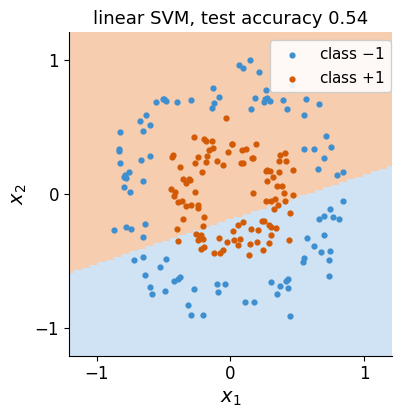

In [2]:
X, y01 = make_circles(n_samples=400, noise=0.12, factor=0.45, random_state=0)   # data seed 0
X = X / np.abs(X).max()                               # coordinates in [-1, 1]
y = np.where(y01 == 1, 1, -1)                         # inner ring +1, outer ring -1
Xtr, ytr, Xte, yte = X[:200], y[:200], X[200:], y[200:]
print(f"training points {len(Xtr)}, test points {len(Xte)}, fraction of class +1 in training: {np.mean(ytr == 1):.2f}")

C_GRID = [0.1, 1, 10, 100]
def fit_svm(Ktr, y):
    """SVM on a precomputed kernel matrix; C chosen by 5-fold cross-validation on the training set."""
    return GridSearchCV(SVC(kernel="precomputed"), {"C": C_GRID}, cv=5).fit(Ktr, y).best_estimator_

lin = fit_svm(Xtr @ Xtr.T, ytr)                       # linear kernel k(x, x') = x . x'
acc_lin = lin.score(Xte @ Xtr.T, yte)
print(f"linear SVM: test accuracy {acc_lin:.3f}")
RESULTS["linear_test_acc"] = acc_lin

g = np.linspace(-1.2, 1.2, 121); GRID = np.array([[u, v] for v in g for u in g])
def draw_map(ax, pred, title, Xs=Xte, ys=yte):
    ax.pcolormesh(g, g, pred.reshape(len(g), len(g)), cmap=CLASS_CMAP, shading="auto", vmin=-1, vmax=1)
    ax.scatter(*Xs[ys == -1].T, s=12, color=BLUE, label="class $-1$")
    ax.scatter(*Xs[ys == 1].T, s=12, color=ORANGE, label="class $+1$")
    ax.set_aspect("equal"); ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1])
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title(title)

fig, ax = plt.subplots(figsize=(4.4, 4.2))
draw_map(ax, lin.predict(GRID @ Xtr.T), f"linear SVM, test accuracy {acc_lin:.2f}")
ax.legend(frameon=True, framealpha=0.9, loc="upper right", bbox_to_anchor=(1.02, 1.0), fontsize=11)
save(fig, "fig_lab073b_linear"); plt.show()

The shaded regions show the class that the linear SVM predicts, blue for $-1$ and orange for $+1$, and the dots are the test points. The line cuts through both rings, and the test accuracy stays near one half, the value of guessing.

## 3. Feature maps, kernels and the support vector machine

A nonlinear boundary in the plane becomes a linear one after the data are mapped into a larger space by a feature map $\boldsymbol\phi(\mathbf x)$. For the rings the quadratic map $\boldsymbol\phi(\mathbf x)=(x_1^2,\sqrt2\,x_1x_2,x_2^2)$ suffices, because the squared radius $x_1^2+x_2^2$ is the sum of the first and the last feature, and a plane in feature space can cut at a fixed radius.

The SVM never needs the features themselves. Its dual formulation [5] finds coefficients $\alpha_i\ge0$ by maximising
$$\sum_{i=1}^M\alpha_i-\frac12\sum_{i,j=1}^M\alpha_i\alpha_j\,y_iy_j\,k(\mathbf x_i,\mathbf x_j),\qquad 0\le\alpha_i\le C,\quad \sum_i\alpha_iy_i=0, \tag{1}$$
where $M$ is the number of training points and the kernel $k(\mathbf x,\mathbf x')=\boldsymbol\phi(\mathbf x)\cdot\boldsymbol\phi(\mathbf x')$ is the inner product of two feature vectors. Problem (1) is convex, so the solver finds its global maximum. The classifier is a weighted sum of kernel values with the training points,
$$f(\mathbf x)=\sum_{i=1}^M\alpha_iy_i\,k(\mathbf x_i,\mathbf x)+b,\qquad y_{\rm pred}=\mathrm{sign}\,f(\mathbf x), \tag{2}$$
which is the content of the representer theorem. Only the training points with $\alpha_i>0$, the support vectors, contribute. The kernel matrix $K_{ij}=k(\mathbf x_i,\mathbf x_j)$ is therefore all the solver needs, and this replacement of features by kernel values is the kernel trick. For the quadratic map the kernel is $k(\mathbf x,\mathbf x')=(\mathbf x\cdot\mathbf x')^2$, which the code checks, and scikit-learn solves (1) from the precomputed matrix. We also rebuild the decision function (2) from the returned coefficients.

In [3]:
def phi_quad(x):
    return np.array([x[0] ** 2, np.sqrt(2) * x[0] * x[1], x[1] ** 2])
assert abs(phi_quad(Xtr[0]) @ phi_quad(Xtr[1]) - (Xtr[0] @ Xtr[1]) ** 2) < TOL     # kernel = inner product

svm_q = fit_svm((Xtr @ Xtr.T) ** 2, ytr)
Kte_q = (Xte @ Xtr.T) ** 2
f_manual = Kte_q[:, svm_q.support_] @ svm_q.dual_coef_[0] + svm_q.intercept_[0]  # equation (2), dual_coef_ = alpha_i y_i
assert np.allclose(f_manual, svm_q.decision_function(Kte_q), atol=1e-10)
print(f"quadratic kernel: {len(svm_q.support_)} support vectors, test accuracy {svm_q.score(Kte_q, yte):.3f}")

quadratic kernel: 71 support vectors, test accuracy 1.000


The quadratic kernel separates the rings, and the decision function written as the kernel sum (2) agrees with the one of scikit-learn. A quantum kernel replaces the quadratic feature map by a quantum state.

## 4. A quantum feature map from angle encoding

We load the two coordinates into two qubits by rotations about the $y$ axis, $\hat R_y(\alpha)=e^{-i\alpha\hat Y/2}$, which turns the Bloch vector of $|0\rangle$ by the angle $\alpha$ towards $|1\rangle$. Qubit 0 carries $x_1$ and qubit 1 carries $x_2$, and one unit of the data corresponds to the angle $\pi$,
$$|\phi(\mathbf x)\rangle=\hat U(\mathbf x)|00\rangle,\qquad \hat U(\mathbf x)=\hat R_y(\pi x_1)\otimes\hat R_y(\pi x_2). \tag{3}$$
This state plays the role of the feature vector, and the quantum kernel is the squared overlap of two such states [1, 2],
$$k(\mathbf x,\mathbf x')=|\langle\phi(\mathbf x)|\phi(\mathbf x')\rangle|^2 . \tag{4}$$
It equals 1 for equal points and lies between 0 and 1 otherwise. For the product state (3) the overlap factorises into one-qubit overlaps, and with $\hat R_y(\alpha)|0\rangle=\cos\frac{\alpha}{2}|0\rangle+\sin\frac{\alpha}{2}|1\rangle$ each of them is $\cos\frac{\alpha}{2}\cos\frac{\alpha'}{2}+\sin\frac{\alpha}{2}\sin\frac{\alpha'}{2}=\cos\frac{\alpha-\alpha'}{2}$, so
$$k(\mathbf x,\mathbf x')=\cos^2\frac{\pi(x_1-x_1')}{2}\,\cos^2\frac{\pi(x_2-x_2')}{2}. \tag{5}$$
Formula (5) is cheap to evaluate classically, so this kernel offers no quantum advantage, and it serves as an example in which every step, from the state to the measured kernel, can be followed. Encodings with entangling gates and repeated layers can produce kernels that are conjectured to be hard to compute classically [1].

The code stores an $N$-qubit state as a tensor with one index per qubit, applies a one-qubit gate by contracting it with the index of its qubit, and checks the result against the Kronecker product and against (5).

In [4]:
def ry(a):
    c, s = jnp.cos(a / 2), jnp.sin(a / 2)
    return jnp.array([[c, -s], [s, c]], dtype=CDTYPE)

def rz(a):
    return jnp.array([[jnp.exp(-0.5j * a), 0], [0, jnp.exp(0.5j * a)]], dtype=CDTYPE)

def apply_1q(psi, G, q):                        # one-qubit gate G on qubit q of the state tensor psi
    return jnp.moveaxis(jnp.tensordot(G, psi, axes=([1], [q])), 0, q)

def zero_state(N):
    return jnp.zeros((2,) * N, dtype=CDTYPE).at[(0,) * N].set(1.0)

def phi_state(x, w=jnp.array([jnp.pi, jnp.pi])):  # equation (3), angles w_k x_k with w_k = pi
    psi = zero_state(2)
    for q in range(2):
        psi = apply_1q(psi, ry(w[q] * x[q]), q)
    return psi.reshape(-1)

def kernel_matrix(SA, SB):                      # equation (4) for all pairs of states
    return jnp.abs(SA.conj() @ SB.T) ** 2

def kernel_formula(A, B):                       # equation (5)
    return np.prod(np.cos(np.pi * (A[:, None, :] - B[None, :, :]) / 2) ** 2, axis=-1)

states = jax.jit(jax.vmap(phi_state))
x_a, x_b = Xtr[0], Xtr[1]
assert jnp.allclose(phi_state(x_a), jnp.kron(ry(np.pi * x_a[0]), ry(np.pi * x_a[1]))[:, 0], atol=TOL)
S_tr, S_te = states(jnp.array(Xtr)), states(jnp.array(Xte))
K_tr, K_te = np.asarray(kernel_matrix(S_tr, S_tr)), np.asarray(kernel_matrix(S_te, S_tr))
assert np.allclose(K_tr, kernel_formula(Xtr, Xtr), atol=TOL) and np.allclose(np.diag(K_tr), 1, atol=TOL)
print("state tensor agrees with the Kronecker product; kernel matrix agrees with equation (5)")
print(f"k(x_a, x_b) = {K_tr[0, 1]:.4f}")

state tensor agrees with the Kronecker product; kernel matrix agrees with equation (5)
k(x_a, x_b) = 0.3558


## 5. Measuring the kernel with the inversion test

A device does not give access to amplitudes, so the overlap (4) has to be measured. The inversion test prepares $|\phi(\mathbf x)\rangle$, applies the inverse circuit of the second point, $\hat U^\dagger(\mathbf x')$, and measures both qubits. The probability of the outcome $00$ is
$$P(00)=|\langle00|\hat U^\dagger(\mathbf x')\hat U(\mathbf x)|00\rangle|^2=|\langle\phi(\mathbf x')|\phi(\mathbf x)\rangle|^2=k(\mathbf x,\mathbf x'), \tag{6}$$
because $\hat U(\mathbf x')|00\rangle=|\phi(\mathbf x')\rangle$. For the map (3) the inverse is $\hat U^\dagger(\mathbf x')=\hat R_y(-\pi x_1')\otimes\hat R_y(-\pi x_2')$. The circuit is run $S$ times, and the kernel is estimated by the frequency $\tilde k=n_{00}/S$ of the outcome $00$. The count $n_{00}$ follows a binomial distribution, so the estimate has the standard error
$$\sigma_{\tilde k}=\sqrt{k(1-k)/S}. \tag{7}$$
A training set of $M$ points needs $M(M-1)/2$ distinct circuits, since the kernel matrix is symmetric and its diagonal equals 1. We simulate the inversion circuit, check (6) and estimate the training kernel matrix with $S=100$ shots per entry.

S = 100: rms error of the entries 0.035, mean of sqrt(k(1-k)/S) 0.031
circuits for the training matrix: 19900 x 100 shots
negative eigenvalues of the estimated matrix: 96


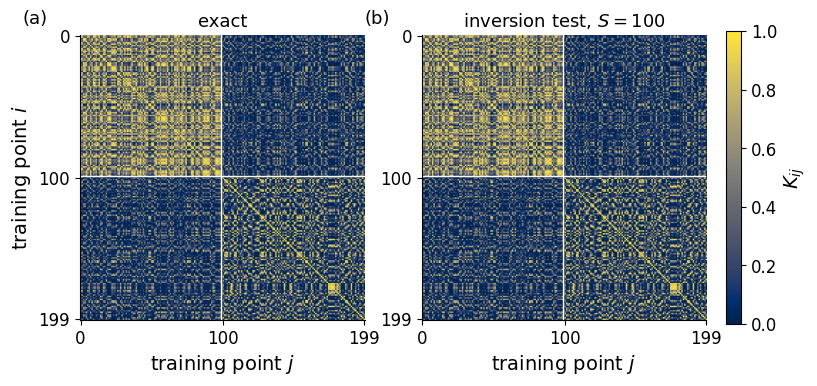

In [5]:
def inversion_test_p00(x, xp):
    psi = phi_state(x).reshape(2, 2)
    for q in range(2):
        psi = apply_1q(psi, ry(-np.pi * xp[q]), q)          # U^dagger(x')
    return float(jnp.abs(psi[0, 0]) ** 2)
assert abs(inversion_test_p00(x_a, x_b) - K_tr[0, 1]) < TOL      # equation (6)

def shot_kernel(K, S, rng, symmetric):
    Kt = rng.binomial(S, np.clip(K, 0, 1)) / S
    if symmetric:                                                   # measure each pair once, diagonal = 1
        Kt = np.triu(Kt, 1); Kt = Kt + Kt.T + np.eye(len(K))
    return Kt

rng_shots = np.random.default_rng(5)                               # shot seed
S_SHOTS = 100
K_tr_S = shot_kernel(K_tr, S_SHOTS, rng_shots, True)
K_te_S = shot_kernel(K_te, S_SHOTS, rng_shots, False)
err = K_tr_S - K_tr
print(f"S = {S_SHOTS}: rms error of the entries {np.sqrt(np.mean(err[np.triu_indices(200, 1)] ** 2)):.3f},"
      f" mean of sqrt(k(1-k)/S) {np.mean(np.sqrt(np.clip(K_tr * (1 - K_tr), 0, None) / S_SHOTS)[np.triu_indices(200, 1)]):.3f}")
print(f"circuits for the training matrix: {200 * 199 // 2} x {S_SHOTS} shots")
print(f"negative eigenvalues of the estimated matrix: {np.sum(np.linalg.eigvalsh(K_tr_S) < -1e-9)}")

order = np.argsort(-ytr, kind="stable")                            # class +1 first
fig, axs = plt.subplots(1, 2, figsize=(8.6, 3.8))
for ax, Km, title in zip(axs, (K_tr, K_tr_S), ("exact", f"inversion test, $S={S_SHOTS}$")):
    im = ax.imshow(Km[np.ix_(order, order)], cmap="cividis", vmin=0, vmax=1)
    n1 = np.sum(ytr == 1)
    ax.axhline(n1 - 0.5, color="w", lw=1); ax.axvline(n1 - 0.5, color="w", lw=1)
    ax.set_title(title); ax.set_xlabel("training point $j$"); ax.set_xticks([0, 100, 199])
    ax.set_yticks([0, 100, 199])
axs[0].set_ylabel("training point $i$")
fig.colorbar(im, ax=axs, fraction=0.03, pad=0.03).set_label(r"$K_{ij}$")
axs[0].text(-0.2, 1.04, "(a)", transform=axs[0].transAxes); axs[1].text(-0.2, 1.04, "(b)", transform=axs[1].transAxes)
save(fig, "fig_lab073b_kernel_matrix"); plt.show()

Both panels show the training kernel matrix with the points sorted by class, the inner ring (class $+1$) first, and white lines separating the classes. Panel (a) is exact, panel (b) is estimated with 100 shots per entry. The upper-left block is bright, since points of the inner ring are close to each other and have large overlaps. The off-diagonal blocks are mostly dark, so points of different rings have small overlaps, while the block of the outer ring mixes large and small values because points far apart on the outer ring have small overlaps. The shot noise adds grain of the size given by (7) and leaves the block structure intact. It also makes about half of the eigenvalues of the estimated matrix negative, whereas an exact kernel matrix has none. These negative eigenvalues are of order one, small compared with the largest eigenvalues, and the SVM solver still returns a classifier.

## 6. Classifying the rings with the quantum kernel

We now pass the exact and the shot-noise kernel matrices to the SVM, with $C$ chosen by five-fold cross-validation on the training set, and evaluate on the test points. The test kernel matrix contains the overlaps of every test point with every training point, as required by (2).

quantum kernel, exact:          test accuracy 0.995, 120 support vectors
quantum kernel, S = 100 shots:  test accuracy 0.995


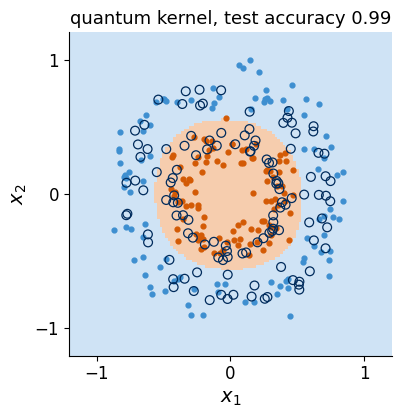

In [6]:
svm_k = fit_svm(K_tr, ytr)
acc_q = svm_k.score(K_te, yte)
acc_q_S = fit_svm(K_tr_S, ytr).score(K_te_S, yte)
print(f"quantum kernel, exact:          test accuracy {acc_q:.3f}, {len(svm_k.support_)} support vectors")
print(f"quantum kernel, S = {S_SHOTS} shots:  test accuracy {acc_q_S:.3f}")
RESULTS.update(quantum_test_acc=acc_q, quantum_test_acc_shots=acc_q_S, shots=S_SHOTS)

K_grid = np.asarray(kernel_matrix(states(jnp.array(GRID)), S_tr))
fig, ax = plt.subplots(figsize=(4.4, 4.2))
draw_map(ax, svm_k.predict(K_grid), f"quantum kernel, test accuracy {acc_q:.2f}")
ax.scatter(*Xtr[svm_k.support_].T, s=40, facecolors="none", edgecolors=NAVY, lw=0.9, label="support vectors")
save(fig, "fig_lab073b_quantum_boundary"); plt.show()

The decision boundary is a closed curve between the rings, and nearly all test points fall on the correct side. The navy circles mark the support vectors, the training points with $\alpha_i>0$ in (2), which lie near the boundary. With 100 shots per entry the test accuracy is unchanged. The rings are an easy task, and the quadratic kernel of Section 3 does as well. The result illustrates how a quantum kernel works and establishes no advantage over a classical kernel.

## 7. Exponential concentration of kernel values

A feature map that spreads the data over the whole state space of $N$ qubits makes two different points almost orthogonal. For two independent random states in a space of dimension $d=2^N$ the squared overlap has mean $1/d$ and a standard deviation close to $1/d$, the typicality of random states that also causes barren plateaus. A kernel built from such a map has off-diagonal values that concentrate around $2^{-N}$ [6]. The kernel matrix then approaches the identity, every training point has nearly the same small overlap with all others, and with a finite number of shots the SVM trained on such a matrix generalises poorly [6]. To resolve a kernel value $k\approx2^{-N}$ with relative error $\epsilon$, equation (7) requires $S\approx(1-k)/(k\epsilon^2)\approx2^N/\epsilon^2$ shots per entry.

We test this with a deep random encoding on $N=2,\dots,10$ qubits. It has $L=N$ layers, each made of $\hat R_z(\vartheta)\hat R_y(\vartheta')$ on every qubit followed by a chain of $\widehat{\mathrm{CZ}}$ gates, and all $2NL$ angles are data components drawn uniformly from $[0,2\pi)$. We evaluate the kernel for 400 pairs of independent data points per $N$.

10.6 s; fitted mean kernel ~ 2^(-0.98 N)
N =  2: mean 2.52e-01, std 2.12e-01, 2^-N = 2.50e-01, shots for 10% error 298
N =  3: mean 1.23e-01, std 1.22e-01, 2^-N = 1.25e-01, shots for 10% error 715
N =  4: mean 6.29e-02, std 6.46e-02, 2^-N = 6.25e-02, shots for 10% error 1490
N =  5: mean 3.04e-02, std 3.20e-02, 2^-N = 3.12e-02, shots for 10% error 3188
N =  6: mean 1.57e-02, std 1.84e-02, 2^-N = 1.56e-02, shots for 10% error 6260
N =  7: mean 7.66e-03, std 7.92e-03, 2^-N = 7.81e-03, shots for 10% error 12952
N =  8: mean 3.95e-03, std 4.24e-03, 2^-N = 3.91e-03, shots for 10% error 25214
N =  9: mean 2.03e-03, std 2.80e-03, 2^-N = 1.95e-03, shots for 10% error 49277
N = 10: mean 1.14e-03, std 1.52e-03, 2^-N = 9.77e-04, shots for 10% error 87387


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


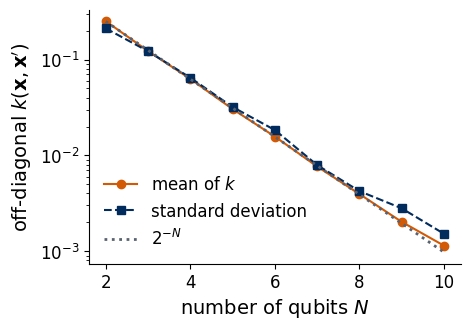

In [7]:
def cz_phases(N):                               # diagonal of the CZ chain on (q, q+1), qubit 0 = most significant bit
    b = (np.arange(2 ** N)[:, None] >> (N - 1 - np.arange(N))) & 1
    return jnp.array(np.prod(np.where(b[:, :-1] & b[:, 1:], -1.0, 1.0), axis=1), dtype=CDTYPE)

def deep_state(angles, N):                      # angles shape (L, N, 2)
    psi, cz = zero_state(N), cz_phases(N)
    for l in range(angles.shape[0]):
        for q in range(N):
            psi = apply_1q(psi, rz(angles[l, q, 1]) @ ry(angles[l, q, 0]), q)
        psi = (cz * psi.reshape(-1)).reshape((2,) * N)
    return psi.reshape(-1)

CZ2 = jnp.diag(jnp.array([1, 1, 1, -1], dtype=CDTYPE))
ang = jnp.array(np.random.default_rng(1).uniform(0, 2 * np.pi, (1, 2, 2)))
assert jnp.allclose(deep_state(ang, 2), CZ2 @ jnp.kron(rz(ang[0, 0, 1]) @ ry(ang[0, 0, 0]), rz(ang[0, 1, 1]) @ ry(ang[0, 1, 0]))[:, 0], atol=TOL)

rng_c = np.random.default_rng(7)                # seed of the random data
NS, PAIRS = np.arange(2, 11), 400
k_mean, k_std = [], []
t0 = time.perf_counter()
for N in NS:
    A = jnp.array(rng_c.uniform(0, 2 * np.pi, (2 * PAIRS, N, N, 2)))
    Sd = jax.jit(jax.vmap(lambda a: deep_state(a, N)))(A)
    kv = np.abs(np.sum(Sd[:PAIRS].conj() * Sd[PAIRS:], axis=1)) ** 2
    k_mean.append(kv.mean()); k_std.append(kv.std())
k_mean, k_std = np.array(k_mean), np.array(k_std)
slope = np.polyfit(NS, np.log2(k_mean), 1)[0]
print(f"{time.perf_counter() - t0:.1f} s; fitted mean kernel ~ 2^({slope:.2f} N)")
for N, m, s in zip(NS, k_mean, k_std):
    print(f"N = {N:2d}: mean {m:.2e}, std {s:.2e}, 2^-N = {2.0 ** -N:.2e}, shots for 10% error {(1 - m) / (m * 0.01):.0f}")
RESULTS["concentration"] = dict(N=NS.tolist(), mean=k_mean.tolist(), std=k_std.tolist(), slope_log2=slope)

fig, ax = plt.subplots(figsize=(4.8, 3.3))
ax.semilogy(NS, k_mean, "o-", color=ORANGE, label="mean of $k$")
ax.semilogy(NS, k_std, "s--", color=NAVY, label="standard deviation")
ax.semilogy(NS, 2.0 ** -NS, ":", color=GRAY, lw=2, label="$2^{-N}$")
ax.set_xlabel("number of qubits $N$"); ax.set_ylabel(r"off-diagonal $k(\mathbf{x},\mathbf{x}')$")
ax.legend(frameon=False, loc="lower left")
save(fig, "fig_lab073b_concentration"); plt.show()

The mean and the standard deviation of the kernel values follow the line $2^{-N}$, so each added qubit halves the typical overlap. At ten qubits a typical kernel entry is about one thousandth, and estimating it with a relative error of 0.1 needs about $10^5$ shots, for every pair of training points. The angle encoding (3) avoids this on two qubits because its angles stay within one turn and its state is a product. A useful quantum kernel needs an encoding that is expressive enough to separate the classes and restrained enough to keep similar data points similar.

## 8. A trainable kernel and kernel-target alignment

The encoding (3) contains a design choice, the angle $\pi$ per unit of data. We make these factors trainable, $\hat R_y(w_1x_1)\otimes\hat R_y(w_2x_2)$, and start from a poor choice, $w_1=w_2=2\pi$, which turns the qubits twice as fast and makes the kernel (5) oscillate across each ring. To train the kernel without fitting an SVM at every step, we use a score computed from the kernel matrix and the labels alone. The ideal kernel matrix for labels $y_i=\pm1$ is $\mathbf y\mathbf y^{T}$, with entries $+1$ for pairs of the same class and $-1$ for pairs of different classes. The kernel-target alignment [3] measures how close $K$ comes to it, as the cosine of the angle between the two matrices regarded as vectors,
$$A(\mathbf w)=\frac{\sum_{ij}K_{ij}\,y_iy_j}{\sqrt{\sum_{ij}K_{ij}^2}\;\sqrt{\sum_{ij}(y_iy_j)^2}}=\frac{\sum_{ij}K_{ij}\,y_iy_j}{M\,\|K\|_F}, \tag{8}$$
where $\|K\|_F$ is the square root of the sum of all squared entries. Same-class pairs with large overlaps raise $A$, and different-class pairs with large overlaps lower it. The entries of a quantum kernel are non-negative, so $A$ cannot reach 1, and for two classes of equal size its largest value is $1/\sqrt2$.

We maximise $A$ by gradient ascent, $\mathbf w\leftarrow\mathbf w+\eta\,\nabla_{\mathbf w}A$, with the step size $\eta=3$ for 100 steps, with the gradient from `jax.grad`. On a device every step would require the full training kernel matrix and its derivatives, which is the main cost of trainable kernels [3]. The SVM is fitted only before and after training.

100 steps in 0.5 s; w/pi: [2. 2.] -> [1.108 1.13 ]
before training: alignment 0.042, test accuracy 0.675
after training:  alignment 0.265, test accuracy 0.990


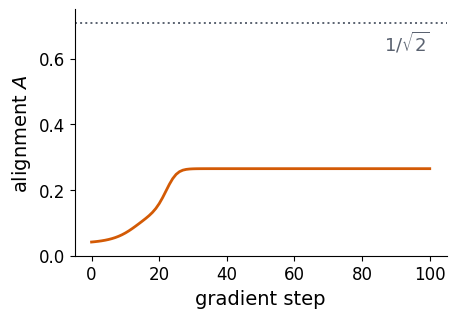

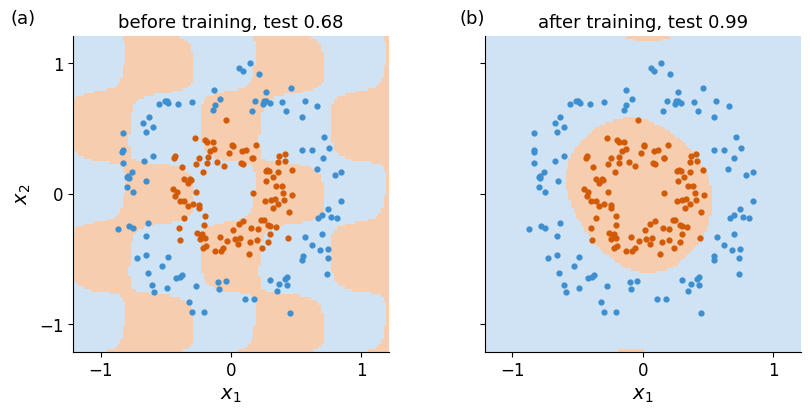

In [8]:
Ytr = jnp.array(ytr, dtype=jnp.float64)
Xtr_j, Xte_j = jnp.array(Xtr), jnp.array(Xte)

def K_w(w, A, B):
    SA = jax.vmap(lambda x: phi_state(x, w))(A); SB = jax.vmap(lambda x: phi_state(x, w))(B)
    return kernel_matrix(SA, SB)

def alignment(w):                                     # equation (8)
    K = K_w(w, Xtr_j, Xtr_j)
    return jnp.sum(K * jnp.outer(Ytr, Ytr)) / (len(Ytr) * jnp.linalg.norm(K))

assert abs(alignment(jnp.array([np.pi, np.pi])) - np.sum(K_tr * np.outer(ytr, ytr)) / (200 * np.linalg.norm(K_tr))) < TOL
yb = np.repeat([1.0, -1.0], 50)                       # balanced labels: the ideal non-negative kernel gives 1/sqrt(2)
K_ideal = (np.outer(yb, yb) + 1) / 2
assert abs(np.sum(K_ideal * np.outer(yb, yb)) / (100 * np.linalg.norm(K_ideal)) - 1 / np.sqrt(2)) < TOL

grad_A = jax.jit(jax.value_and_grad(alignment))
w = jnp.array([2 * np.pi, 2 * np.pi]); w0 = w
LR, STEPS = 3.0, 100
history = []
t0 = time.perf_counter()
for step in range(STEPS):
    A_val, gA = grad_A(w)
    history.append(float(A_val))
    w = w + LR * gA                                   # gradient ascent
history.append(float(alignment(w)))
print(f"{STEPS} steps in {time.perf_counter() - t0:.1f} s; w/pi: {np.asarray(w0) / np.pi} -> {np.round(np.asarray(w) / np.pi, 3)}")

def evaluate(wv):
    Ktr_, Kte_ = np.asarray(K_w(wv, Xtr_j, Xtr_j)), np.asarray(K_w(wv, Xte_j, Xtr_j))
    svm_ = fit_svm(Ktr_, ytr)
    return svm_, Ktr_, svm_.score(Kte_, yte)
svm0, K0, acc0 = evaluate(w0)
svm1, K1, acc1 = evaluate(w)
print(f"before training: alignment {history[0]:.3f}, test accuracy {acc0:.3f}")
print(f"after training:  alignment {history[-1]:.3f}, test accuracy {acc1:.3f}")
RESULTS["trainable"] = dict(w0_over_pi=(np.asarray(w0) / np.pi).tolist(), w_over_pi=(np.asarray(w) / np.pi).tolist(),
                            A0=history[0], A1=history[-1], acc0=acc0, acc1=acc1, steps=STEPS, lr=LR)

fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.plot(history, color=ORANGE, lw=2)
ax.axhline(1 / np.sqrt(2), color=GRAY, ls=":", lw=1.4); ax.text(STEPS, 1 / np.sqrt(2) - 0.02, r"$1/\sqrt{2}$", color=GRAY, ha="right", va="top")
ax.set_xlabel("gradient step"); ax.set_ylabel("alignment $A$"); ax.set_ylim(0, 0.75)
save(fig, "fig_lab073b_alignment"); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(8.8, 4.2))
for ax, wv, svm_, acc_, lab in ((axs[0], w0, svm0, acc0, "before"), (axs[1], w, svm1, acc1, "after")):
    Kg = np.asarray(K_w(wv, jnp.array(GRID), Xtr_j))
    draw_map(ax, svm_.predict(Kg), f"{lab} training, test {acc_:.2f}")
axs[1].set_ylabel(""); axs[1].set_yticklabels([])
axs[0].text(-0.2, 1.04, "(a)", transform=axs[0].transAxes); axs[1].text(-0.08, 1.04, "(b)", transform=axs[1].transAxes)
fig.tight_layout(); save(fig, "fig_lab073b_trained_maps"); plt.show()

The alignment grows slowly for about twenty steps, rises quickly to about 0.27 and then stays constant, well below the bound $1/\sqrt2$ because points far apart on the same ring still have small overlaps. The trained factors end close to $\pi$, near the value $\pi$ used in Section 4. Panel (a) shows the decision map of the initial kernel, whose fast oscillations produce a fragmented boundary and a low test accuracy. Panel (b) shows the trained kernel, which draws one closed boundary between the rings. The alignment was computed from the training labels only, and the test accuracy confirms that a higher alignment gave a better classifier here. The alignment landscape of a trainable kernel has local maxima, and a start from $w_1=w_2=3\pi$ ends at a local maximum with a much lower alignment (Exercise 4).

## 9. Exercises

1. Plot the test accuracy of the quantum-kernel SVM against the number of shots $S=1,3,10,30,100,1000$ per kernel entry, averaged over five shot seeds, and compare with the size of the error (7).
2. Add a $\widehat{\mathrm{CZ}}$ gate and a second encoding layer to the map (3), $\hat U(\mathbf x)\,\widehat{\mathrm{CZ}}\,\hat U(\mathbf x)$. Check numerically that the kernel no longer factorises as in (5), and compare the test accuracy with Section 6.
3. Evaluate the kernel (4) of the map (3) generalised to $N$ qubits, $\bigotimes_q\hat R_y(x_q)$ with each $x_q$ uniform in $[0,2\pi)$. Show from (5) that the mean kernel value is $2^{-N}$, and repeat with the angles drawn from $[0,0.2]$. Explain the difference with the argument of Section 7.
4. Scan the alignment (8) for $w_1=w_2=w$ between $0.5\pi$ and $4\pi$ and mark its local maxima. Start gradient ascent from $w_1=w_2=3\pi$, evaluate the SVM with the resulting kernel and compare with Section 8.
5. Show that a trainable gate placed after the last encoding gate, $\hat W(\boldsymbol\theta)\hat U(\mathbf x)|00\rangle$, cannot change the kernel (4). Find where trainable gates must be placed so that they change the kernel.

In [9]:
RESULTS["runtime_seconds"] = time.perf_counter() - started
(RES / "lab073b_results.json").write_text(json.dumps(RESULTS, indent=2, default=float))
print(f"results written to {RES / 'lab073b_results.json'}")
print(f"runtime of the whole notebook: {RESULTS['runtime_seconds']:.1f} s")

results written to classroom_results/lab073b_results.json
runtime of the whole notebook: 20.0 s


## 10. Summary

A support vector machine needs the data only through a kernel, the inner product of feature vectors, and it finds the classifier by a convex optimisation. A quantum kernel takes as feature vector the state prepared by a data-dependent circuit and as kernel the squared overlap of two such states, which a device measures as the probability of returning to $|00\rangle$ in the inversion test. Angle encoding on two qubits gave a kernel that separates two concentric rings, and the estimate from 100 shots per entry classified the test points about as well as the exact kernel. The kernel of two-qubit angle encoding has the classical formula (5), so this example illustrates the method without any quantum advantage. A deep random encoding on many qubits makes the kernel values concentrate around $2^{-N}$, so the kernel matrix approaches the identity and the number of shots per entry grows exponentially. Training the encoding by maximising the kernel-target alignment, a score computed from the training labels without the SVM, repaired a poorly chosen encoding and raised the test accuracy.

## References

[1] V. Havlíček, A. D. Córcoles, K. Temme, A. W. Harrow, A. Kandala, J. M. Chow, and J. M. Gambetta, Supervised learning with quantum-enhanced feature spaces, Nature **567**, 209 (2019), [doi:10.1038/s41586-019-0980-2](https://doi.org/10.1038/s41586-019-0980-2).

[2] M. Schuld and N. Killoran, Quantum machine learning in feature Hilbert spaces, Phys. Rev. Lett. **122**, 040504 (2019), [doi:10.1103/PhysRevLett.122.040504](https://doi.org/10.1103/PhysRevLett.122.040504).

[3] T. Hubregtsen, D. Wierichs, E. Gil-Fuster, P.-J. H. S. Derks, P. K. Faehrmann, and J. J. Meyer, Training quantum embedding kernels on near-term quantum computers, Phys. Rev. A **106**, 042431 (2022), [doi:10.1103/PhysRevA.106.042431](https://doi.org/10.1103/PhysRevA.106.042431).

[4] F. Pedregosa et al., Scikit-learn: Machine learning in Python, J. Mach. Learn. Res. **12**, 2825 (2011), [jmlr.org/papers/v12/pedregosa11a](https://jmlr.org/papers/v12/pedregosa11a.html).

[5] C. Cortes and V. Vapnik, Support-vector networks, Mach. Learn. **20**, 273 (1995), [doi:10.1007/BF00994018](https://doi.org/10.1007/BF00994018).

[6] S. Thanasilp, S. Wang, M. Cerezo, and Z. Holmes, Exponential concentration in quantum kernel methods, Nat. Commun. **15**, 5200 (2024), [doi:10.1038/s41467-024-49287-w](https://doi.org/10.1038/s41467-024-49287-w).